In [ ]:
!pip install --upgrade keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 2.4 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 2.15.0
    Uninstalling keras-2.15.0:
      Successfully uninstalled keras-2.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.0.4 which is incompatible.


In [ ]:
import keras

print(keras.__version__)

3.0.4


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
調整X_train的圖片尺寸...
調整X_test的圖片尺寸...
17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape                  ┃     Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ mobilenet_1.00_224 (Functional)    │ (None, 7, 7, 1024)            │   3,228,864 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dropout (Dropout)                  │ (None, 7, 7, 1024)            │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ global_average_pooling2d           │ (None, 1024)                  │           0 │
│ (GlobalAveragePooling2D)           │                               │             │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dropout_1 (Dropout)                │ (None, 1024)                  │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense (Dense)                      │ (None, 10)                    │      10,250 │
└────────────────────────────────────┴───────────────────────────────┴─────────────┘

 Total params: 3,239,114 (12.36 MB)

 Trainable params: 3,217,226 (12.27 MB)

 Non-trainable params: 21,888 (85.50 KB)

Epoch 1/17
157/157 - 32s - 202ms/step - accuracy: 0.4476 - loss: 1.7471 - val_accuracy: 0.7610 - val_loss: 0.7144
Epoch 2/17
157/157 - 6s - 36ms/step - accuracy: 0.6960 - loss: 0.9005 - val_accuracy: 0.7790 - val_loss: 0.6031
Epoch 3/17
157/157 - 5s - 35ms/step - accuracy: 0.7514 - loss: 0.7168 - val_accuracy: 0.7950 - val_loss: 0.5515
Epoch 4/17
157/157 - 5s - 33ms/step - accuracy: 0.7856 - loss: 0.6326 - val_accuracy: 0.8180 - val_loss: 0.5152
Epoch 5/17
157/157 - 5s - 35ms/step - accuracy: 0.7906 - loss: 0.6028 - val_accuracy: 0.8180 - val_loss: 0.4981
Epoch 6/17
157/157 - 11s - 67ms/step - accuracy: 0.8120 - loss: 0.5502 - val_accuracy: 0.8260 - val_loss: 0.4844
Epoch 7/17
157/157 - 10s - 66ms/step - accuracy: 0.8124 - loss: 0.5327 - val_accuracy: 0.8310 - val_loss: 0.4948
Epoch 8/17
157/157 - 6s - 37ms/step - accuracy: 0.8182 - loss: 0.5131 - val_accuracy: 0.8310 - val_loss: 0.4817
Epoch 9/17
157/157 - 5s - 34ms/step - accuracy: 0.8256 - loss: 0.5002 - val_accuracy: 0.8340 - val_l

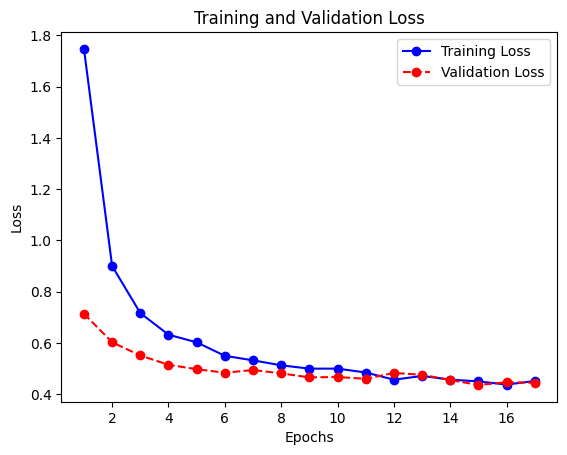

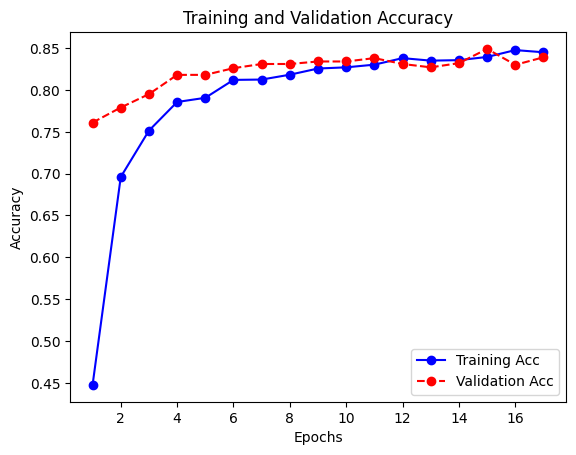

In [ ]:
import numpy as np
from keras.datasets import cifar10
from keras.applications.mobilenet import MobileNet, preprocess_input
from keras import Sequential
from keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D
from keras.utils import to_categorical
from PIL import Image
import warnings

warnings.filterwarnings("ignore")
# 指定亂數種子
np.random.seed(10)
# 載入資料集
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
# 打亂 2 個 Numpy 陣列
def randomize(a, b):
    permutation = list(np.random.permutation(a.shape[0]))
    shuffled_a = a[permutation]
    shuffled_b = b[permutation]

    return shuffled_a, shuffled_b

X_train, y_train = randomize(X_train, y_train)
X_test, y_test = randomize(X_test, y_test)
# 取出部分的訓練和測試資料
X_train = X_train[:5000]
y_train = y_train[:5000]
X_test = X_test[:1000]
y_test = y_test[:1000]
# One-hot編碼
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)
# 調整X_train的圖片尺寸
print("調整X_train的圖片尺寸...")
X_train_new = np.array(
  [np.asarray(Image.fromarray(X_train[i]).resize(
          (224, 224))) for i in range(0, len(X_train))])
X_train_new = X_train_new.astype("float32")
# 訓練資料的資料前處理
train_input = preprocess_input(X_train_new)
# 調整X_test的圖片尺寸
print("調整X_test的圖片尺寸...")
X_test_new = np.array(
  [np.asarray(Image.fromarray(X_test[i]).resize(
          (224, 224))) for i in range(0, len(X_test))])
X_test_new = X_test_new.astype("float32")
# 測試資料的資料前處理
test_input = preprocess_input(X_test_new)
# 定義模型
# 載入 MobileNet 模型
mobilenet_model = MobileNet(weights="imagenet",
                            include_top=False)
model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(mobilenet_model)
model.add(Dropout(0.5))
model.add(GlobalAveragePooling2D())
model.add(Dropout(0.5))
model.add(Dense(10, activation="softmax"))
model.summary()   # 顯示模型摘要資訊
# 凍結上層模型
mobilenet_model.trainable = False
# 編譯模型
model.compile(loss="categorical_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 訓練模型
history = model.fit(train_input, y_train,
                    validation_data=(test_input, y_test),
                    epochs=17, batch_size=32, verbose=2)
# 評估模型
print("\nTesting ...")
loss, accuracy = model.evaluate(test_input, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示圖表來分析模型的訓練過程
import matplotlib.pyplot as plt
# 顯示訓練和驗證損失
loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo-", label="Training Loss")
plt.plot(epochs, val_loss, "ro--", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "bo-", label="Training Acc")
plt.plot(epochs, val_acc, "ro--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()